# Trabalho Final - Disciplina de IA - PPGI - Unirio

* Bruce Notario
* Marcus Monteiro
* Patricia Santos


# Etapa 02 - Entendimento dos dados

In [3]:
from constantes import ARQUIVO_VOTOS, ARQUIVO_VOTACOES, VOTACAO_EXEMPLO_ID
import pandas as pd
import matplotlib.pyplot as plt

# ARQUIVO DE VOTOS

**Entenda o processo legislativo**

O processo legislativo compreende a elaboração, análise e votação de vários tipos de propostas: leis ordinárias, medidas provisórias, emendas à Constituição, decretos legislativos e resoluções, entre outras. Cada tipo de proposta segue um caminho (tramitação) diferente.

Fonte: https://www.camara.leg.br/entenda-o-processo-legislativo/

In [4]:
df_votacoes = pd.read_csv(filepath_or_buffer=ARQUIVO_VOTACOES, sep=";")
df_votos = pd.read_csv(filepath_or_buffer=ARQUIVO_VOTOS, sep=";")

In [5]:
df_votos.head(3)

,idVotacao,uriVotacao,dataHoraVoto,voto,deputado_id,deputado_uri,deputado_nome,deputado_siglaPartido,deputado_uriPartido,deputado_siglaUf,deputado_idLegislatura,deputado_urlFoto
0,106701-223,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-11-05T12:41:17,Sim,204379,https://dadosabertos.camara.leg.br/api/v2/depu...,Acácio Favacho,MDB,https://dadosabertos.camara.leg.br/api/v2/part...,AP,57,https://www.camara.leg.br/internet/deputado/ba...
1,106701-223,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-11-05T12:31:16,Sim,220714,https://dadosabertos.camara.leg.br/api/v2/depu...,Adail Filho,REPUBLICANOS,https://dadosabertos.camara.leg.br/api/v2/part...,AM,57,https://www.camara.leg.br/internet/deputado/ba...
2,106701-223,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-11-05T12:32:08,Sim,221328,https://dadosabertos.camara.leg.br/api/v2/depu...,Adilson Barroso,PL,https://dadosabertos.camara.leg.br/api/v2/part...,SP,57,https://www.camara.leg.br/internet/deputado/ba...


In [6]:
df_votos.info()

<class 'pandas.DataFrame'>
RangeIndex: 175067 entries, 0 to 175066
Data columns (total 12 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   idVotacao               175067 non-null  str  
 1   uriVotacao              175067 non-null  str  
 2   dataHoraVoto            175067 non-null  str  
 3   voto                    174646 non-null  str  
 4   deputado_id             175067 non-null  int64
 5   deputado_uri            175067 non-null  str  
 6   deputado_nome           175067 non-null  str  
 7   deputado_siglaPartido   175067 non-null  str  
 8   deputado_uriPartido     175067 non-null  str  
 9   deputado_siglaUf        175067 non-null  str  
 10  deputado_idLegislatura  175067 non-null  int64
 11  deputado_urlFoto        175067 non-null  str  
dtypes: int64(2), str(10)
memory usage: 16.0 MB


**Fatos:**

- Praticamente todos os campos de votos são do tipo texto.
    
**Acões:**

- Se faz necessário converter a DATA/HORA do voto para datetime.

In [7]:
df_votos.describe()

,deputado_id,deputado_idLegislatura
count,175067.000000,175067.0
mean,181925.054522,57.0
std,49744.746606,0.0
min,62881.000000,57.0
25%,160592.000000,57.0
50%,204460.000000,57.0
75%,220598.000000,57.0
max,234788.000000,57.0


**Fatos:**

- Os campos numéricos são do tipo ID.
    
**Acões:**

- Nenhuma.

In [8]:
df_votos.nunique()

idVotacao                    550
uriVotacao                   550
dataHoraVoto              100133
voto                           5
deputado_id                  551
deputado_uri                 551
deputado_nome                553
deputado_siglaPartido         20
deputado_uriPartido           22
deputado_siglaUf              27
deputado_idLegislatura         1
deputado_urlFoto             551
dtype: int64

**Fatos:**

- Existem 5 diferentes valores de voto;
- Há votos de todos os 27 estados;
- Todos os votos são de uma mesma legislatura (há somente uma no arquivo);
- Há 20 partidos diferentes representados nos votos.
    
**Acões:**

- Nenhuma.

In [9]:
df_votos["voto"].unique()

<StringArray>
['Sim', 'Artigo 17', 'Não', 'Abstenção', 'Obstrução', nan]
Length: 6, dtype: str

**Fatos:**

- Os votos podem ser: 'Sim', 'Artigo 17', 'Não', 'Abstenção', 'Obstrução', nan
    
**Acões:**

- Precisamos pensar em como tratar 'Artigo 17', 'Abstenção', 'Obstrução' e nan.

In [10]:
df_votos.isnull().sum()

idVotacao                   0
uriVotacao                  0
dataHoraVoto                0
voto                      421
deputado_id                 0
deputado_uri                0
deputado_nome               0
deputado_siglaPartido       0
deputado_uriPartido         0
deputado_siglaUf            0
deputado_idLegislatura      0
deputado_urlFoto            0
dtype: int64

**Fatos:**

- Os únicos dados null são dados de votos (há 421 votos registrados como null);
    
**Acões:**

- Precisamos tratar os valores null para os votos.

In [11]:
df_votos.isna().sum()

idVotacao                   0
uriVotacao                  0
dataHoraVoto                0
voto                      421
deputado_id                 0
deputado_uri                0
deputado_nome               0
deputado_siglaPartido       0
deputado_uriPartido         0
deputado_siglaUf            0
deputado_idLegislatura      0
deputado_urlFoto            0
dtype: int64

**Fatos:**

- Os únicos dados na são dados de votos (há 421 votos registrados como na);
    
**Acões:**

- Precisamos tratar os valores na para os votos.

# Investigando voto no 'Artigo 17'

In [12]:
tipos_possiveis_de_voto = df_votos.groupby(["voto"])["voto"]

<BarContainer object of 5 artists>

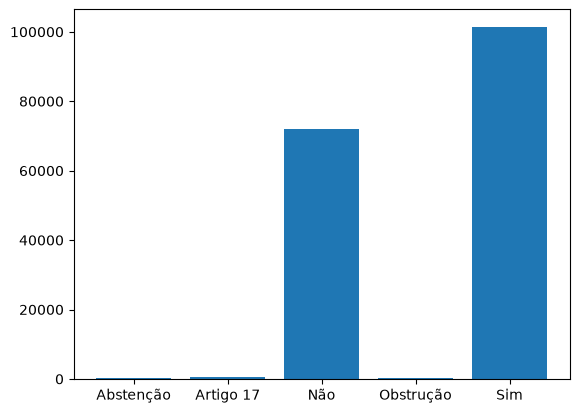

In [13]:
plt.bar(tipos_possiveis_de_voto.count().index, tipos_possiveis_de_voto.count())

In [14]:
tipos_possiveis_de_voto.count()

voto
Abstenção       347
Artigo 17       420
Não           72098
Obstrução       375
Sim          101406
Name: voto, dtype: int64

In [15]:
votos_artigo_17 = df_votos[df_votos["voto"] == "Artigo 17"]
votos_artigo_17[
    [
        "idVotacao",
        "dataHoraVoto",
        "deputado_id",
        "deputado_nome",
        "deputado_siglaPartido",
        "deputado_siglaUf",
    ]
].head(5)

,idVotacao,dataHoraVoto,deputado_id,deputado_nome,deputado_siglaPartido,deputado_siglaUf
61,106701-223,2025-11-05T12:30:41,204426,Carlos Veras,PT,PE
492,106701-227,2025-11-05T12:46:33,204426,Carlos Veras,PT,PE
1284,146708-38,2025-08-12T18:21:52,160674,Hugo Motta,REPUBLICANOS,PB
1648,1672171-148,2025-10-02T11:30:24,160674,Hugo Motta,REPUBLICANOS,PB
2075,2121642-102,2025-05-27T18:54:34,160674,Hugo Motta,REPUBLICANOS,PB


In [16]:
sorted(votos_artigo_17["deputado_nome"].unique())

['Alberto Fraga',
 'Altineu Côrtes',
 'Amanda Gentil',
 'Antonio Carlos Rodrigues',
 'Carlos Veras',
 'Celso Russomanno',
 'Charles Fernandes',
 'Delegada Katarina',
 'Dr. Zacharias Calil',
 'Elmar Nascimento',
 'Erika Kokay',
 'Gilberto Nascimento',
 'Helder Salomão',
 'Hildo Rocha',
 'Hugo Motta',
 'Icaro de Valmir',
 'Jack Rocha',
 'Luiz Carlos Motta',
 'Luiz Lima',
 'Lula da Fonte',
 'Paulo Folletto',
 'Pedro Lucas Fernandes',
 'Ruy Carneiro',
 'Wilson Santiago']

In [17]:
votacao_exemplo = df_votacoes[df_votacoes["id"] == VOTACAO_EXEMPLO_ID]
votacao_exemplo

,id,uri,data,dataHoraRegistro,idOrgao,uriOrgao,siglaOrgao,idEvento,uriEvento,aprovacao,votosSim,votosNao,votosOutros,descricao,ultimaAberturaVotacao_dataHoraRegistro,ultimaAberturaVotacao_descricao,ultimaApresentacaoProposicao_dataHoraRegistro,ultimaApresentacaoProposicao_descricao,ultimaApresentacaoProposicao_idProposicao,ultimaApresentacaoProposicao_uriProposicao
10946,106701-223,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-11-05,2025-11-05T12:42:37,180,https://dadosabertos.camara.leg.br/api/v2/orga...,PLEN,80210,https://dadosabertos.camara.leg.br/api/v2/even...,1.0,427,1,1,Aprovada a Subemenda Substitutiva Global ao Pr...,2025-11-05T12:29:35,Votação em turno único.,2025-11-05T12:25:20,Parecer às Emendas de Plenário proferido pelo ...,2581920,https://dadosabertos.camara.leg.br/api/v2/prop...


In [18]:
votacao_exemplo[
    [
        "data",
        "siglaOrgao",
        "aprovacao",
        "votosSim",
        "votosNao",
        "votosOutros",
        "descricao",
        "ultimaApresentacaoProposicao_descricao",
    ]
]

,data,siglaOrgao,aprovacao,votosSim,votosNao,votosOutros,descricao,ultimaApresentacaoProposicao_descricao
10946,2025-11-05,PLEN,1.0,427,1,1,Aprovada a Subemenda Substitutiva Global ao Pr...,Parecer às Emendas de Plenário proferido pelo ...


In [19]:
print(votacao_exemplo["descricao"].values[0])

Aprovada a Subemenda Substitutiva Global ao Projeto de Lei nº 347, de 2003, adotado pelo relator da Comissão de Meio Ambiente e Desenvolvimento Sustentável, ressalvado o destaque. Sim: 427; Não: 1; Total: 428.


In [20]:
votos_votacao_exemplo = df_votos[df_votos["idVotacao"] == VOTACAO_EXEMPLO_ID]
votos_votacao_exemplo.head(5)

,idVotacao,uriVotacao,dataHoraVoto,voto,deputado_id,deputado_uri,deputado_nome,deputado_siglaPartido,deputado_uriPartido,deputado_siglaUf,deputado_idLegislatura,deputado_urlFoto
0,106701-223,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-11-05T12:41:17,Sim,204379,https://dadosabertos.camara.leg.br/api/v2/depu...,Acácio Favacho,MDB,https://dadosabertos.camara.leg.br/api/v2/part...,AP,57,https://www.camara.leg.br/internet/deputado/ba...
1,106701-223,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-11-05T12:31:16,Sim,220714,https://dadosabertos.camara.leg.br/api/v2/depu...,Adail Filho,REPUBLICANOS,https://dadosabertos.camara.leg.br/api/v2/part...,AM,57,https://www.camara.leg.br/internet/deputado/ba...
2,106701-223,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-11-05T12:32:08,Sim,221328,https://dadosabertos.camara.leg.br/api/v2/depu...,Adilson Barroso,PL,https://dadosabertos.camara.leg.br/api/v2/part...,SP,57,https://www.camara.leg.br/internet/deputado/ba...
3,106701-223,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-11-05T12:33:17,Sim,204560,https://dadosabertos.camara.leg.br/api/v2/depu...,Adolfo Viana,PSDB,https://dadosabertos.camara.leg.br/api/v2/part...,BA,57,https://www.camara.leg.br/internet/deputado/ba...
4,106701-223,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-11-05T12:32:50,Sim,204528,https://dadosabertos.camara.leg.br/api/v2/depu...,Adriana Ventura,NOVO,https://dadosabertos.camara.leg.br/api/v2/part...,SP,57,https://www.camara.leg.br/internet/deputado/ba...


In [21]:
votos_votacao_exemplo["voto"].value_counts()

voto
Sim          427
Artigo 17      1
Não            1
Name: count, dtype: int64

In [22]:
votos_votacao_exemplo[votos_votacao_exemplo["voto"] == "Artigo 17"]

,idVotacao,uriVotacao,dataHoraVoto,voto,deputado_id,deputado_uri,deputado_nome,deputado_siglaPartido,deputado_uriPartido,deputado_siglaUf,deputado_idLegislatura,deputado_urlFoto
61,106701-223,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-11-05T12:30:41,Artigo 17,204426,https://dadosabertos.camara.leg.br/api/v2/depu...,Carlos Veras,PT,https://dadosabertos.camara.leg.br/api/v2/part...,PE,57,https://www.camara.leg.br/internet/deputado/ba...


In [23]:
print(votacao_exemplo["ultimaApresentacaoProposicao_descricao"].values[0])

Parecer às Emendas de Plenário proferido pelo Relator, Dep. Fred Costa (PRD-MG) pela:
• Comissão de Meio Ambiente e Desenvolvimento Sustentável, que conclui pela rejeição das Emendas de Plenário nºs 2, 3, 4 ,5, 6 e 7, e pela aprovação da Emenda de Plenário nº 1, na forma da Subemenda Substitutiva adotada.
• Comissão de Constituição e Justiça e de Cidadania, que conclui pela constitucionalidade, juridicidade e boa técnica legislativa; e, no mérito, pela rejeição das Emendas de Plenário nºs 2, 3, 4 ,5, 6 e 7, e pela aprovação da Emenda de Plenário nº 1, na forma da Subemenda Substitutiva adotada pelo relator da Comissão de Meio Ambiente e Desenvolvimento Sustentável.


In [24]:
votacao_qualquer = df_votos[df_votos["idVotacao"] == VOTACAO_EXEMPLO_ID].groupby("voto")

<BarContainer object of 3 artists>

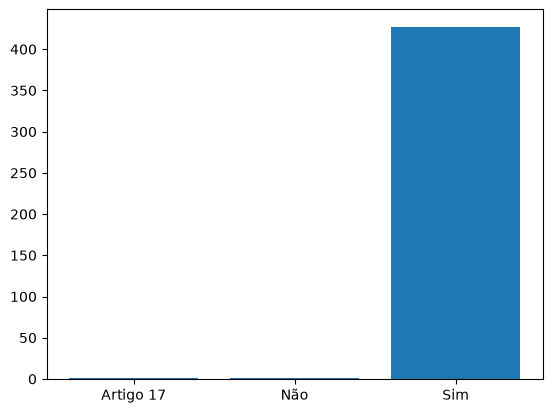

In [25]:
plt.bar(votacao_qualquer["voto"].count().index, votacao_qualquer["voto"].count())

In [26]:
votacao_qualquer["voto"].count()

voto
Artigo 17      1
Não            1
Sim          427
Name: voto, dtype: int64

In [27]:
df_votos[df_votos["voto"] == "Artigo 17"]["idVotacao"].value_counts().max()

np.int64(2)

O voto 'Artigo 17' ocorre, no máximo, 2 vezes por sessão.

In [28]:
df_votos[df_votos["voto"] == "Artigo 17"]["idVotacao"].value_counts().min()

np.int64(1)

O voto 'Artigo 17' pode ocorrer apenas 1 vez na sessão.

In [29]:
ids_votacoes_com_mais_de_um_voto_artigo_17 = []
for idVotacao, votacoes in df_votos[df_votos["voto"] == "Artigo 17"].groupby(
    "idVotacao"
):
    if votacoes["idVotacao"].count() > 1:
        ids_votacoes_com_mais_de_um_voto_artigo_17.append(idVotacao)
df_votacoes[df_votacoes["id"].isin(ids_votacoes_com_mais_de_um_voto_artigo_17)].head(5)

,id,uri,data,dataHoraRegistro,idOrgao,uriOrgao,siglaOrgao,idEvento,uriEvento,aprovacao,votosSim,votosNao,votosOutros,descricao,ultimaAberturaVotacao_dataHoraRegistro,ultimaAberturaVotacao_descricao,ultimaApresentacaoProposicao_dataHoraRegistro,ultimaApresentacaoProposicao_descricao,ultimaApresentacaoProposicao_idProposicao,ultimaApresentacaoProposicao_uriProposicao
29,2438467-41,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-02-12,2025-02-12T16:42:30,180,https://dadosabertos.camara.leg.br/api/v2/orga...,PLEN,75404,https://dadosabertos.camara.leg.br/api/v2/even...,0.0,125,236,4,Rejeitado o Requerimento. Sim: 125; Não: 236; ...,NaN,NaN,NaN,NaN,0,NaN
1385,2498967-8,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-04-23,2025-04-23T18:06:30,180,https://dadosabertos.camara.leg.br/api/v2/orga...,PLEN,76066,https://dadosabertos.camara.leg.br/api/v2/even...,1.0,267,116,2,Aprovado o Requerimento de Urgência (Art. 155 ...,NaN,NaN,NaN,NaN,0,NaN
1495,2456731-71,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-04-29,2025-04-29T20:02:39,180,https://dadosabertos.camara.leg.br/api/v2/orga...,PLEN,76158,https://dadosabertos.camara.leg.br/api/v2/even...,1.0,261,108,6,Aprovado o Substitutivo ao Projeto de Lei nº 3...,2025-04-29T18:48:20,Votação em turno único.,2025-04-23T18:41:59,Leitura realizada em Plenário pelo Dep. Carlos...,2499908,https://dadosabertos.camara.leg.br/api/v2/prop...
1532,2233324-75,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-05-05,2025-05-05T21:43:00,180,https://dadosabertos.camara.leg.br/api/v2/orga...,PLEN,76214,https://dadosabertos.camara.leg.br/api/v2/even...,0.0,108,261,3,Rejeitado o Requerimento. Sim: 108; Não: 261; ...,NaN,NaN,2025-05-05T21:11:13,"Parecer proferido em Plenário pela Relatora, D...",2503829,https://dadosabertos.camara.leg.br/api/v2/prop...
2558,2233324-100,https://dadosabertos.camara.leg.br/api/v2/vota...,2025-05-26,2025-05-26T21:14:56,180,https://dadosabertos.camara.leg.br/api/v2/orga...,PLEN,76513,https://dadosabertos.camara.leg.br/api/v2/even...,NaN,231,202,10,Mantido o texto. Sim: 231; Não: 202; Abstenção...,2025-05-26T20:50:27,"Votação do DTQ 2 (PL, Federação Brasil da Espe...",2025-05-05T22:15:03,Parecer às Emendas de Plenário proferido pela ...,2503845,https://dadosabertos.camara.leg.br/api/v2/prop...


Essas são as votações com mais do que 1 voto no artigo 17.

**Fatos:**

- Votar no 'Artigo 17' significa 'Voto do Presidente' (comparou-se o que está nos dados com o que é exibido no site da Câmara dos Deputados - ver em https://www.camara.leg.br/presenca-comissoes/votacao-portal?reuniao=76513&itemVotacao=12869).
    
**Acões:**

- Os votos no 'Artigo 17' precisam ser trocados por 'Voto do Presidente'
- Talvez os 'Voto do Presidente' possam ser excluídos em cálculos de correção (possivelmente do trabalho inteiro)

**Votação**

A votação ocorre logo após a discussão da matéria. A votação é o momento de tomada de decisão, quando os parlamentares declaram seu voto: a favor, contrário ou abstenção. Também é possível que uma bancada entre em obstrução.

Há 2 tipos de votação: a pública e a secreta. As votações públicas podem ser pelo processo simbólico ou nominal.

A votação em Comissão é sobre o parecer do Relator e a votação em Plenário é sobre a matéria. No momento da votação ainda podem ser oferecidos destaques.

Fonte: https://educacaoadistancia.camara.leg.br/clique_regimento/categoria/9

**Votação nominal**

A votação pelo processo nominal ocorre por meio da identificação do parlamentar junto ao sistema de votação eletrônica e permite ao público o conhecimento de quem votou a favor, contra, de quem se absteve ou permaneceu em obstrução. A votação nominal pode:

- decorrer de exigência constitucional ou regimental - quando há exigência de quórum de maioria absoluta ou quóruns qualificados (por exemplo, PECs e PLPs sempre serão submetidos à votação pelo processo nominal em Plenário);
- ser concedida de ofício pelo Presidente do Colegiado;
- ser aprovada pelo Plenário por meio do requerimento de votação pelo processo nominal ou;
- decorrer de pedido de verificação de votação após uma votação pelo processo simbólico.

RICD, Art. 187.

Fonte: https://educacaoadistancia.camara.leg.br/clique_regimento/card/194

**Abstenção**

Ato pelo qual o parlamentar exerce o direito de não optar por uma das alternativas disponíveis em votação. É computada exclusivamente no quórum de presença exigido para a validação da deliberação.

 - RICD, arts. 180, § 2º, e 183, § 2º; RISF, arts. 288, § 2º, 294, I, “b”, e 298.
- Tradução: Abstention (Inglês); Abstención (Espanhol).


Fonte: https://www.congressonacional.leg.br/legislacao-e-publicacoes/glossario-legislativo

**Obstrução**

Considera-se obstrução qualquer medida utilizada pelos Deputados, com amparo no Regimento, que obste ou atrase a tramitação de uma matéria.

A forma mais comum de obstrução é a declaração de “em obstrução” feita por bancada como forma de orientar seus membros a não votarem em determinada matéria, negando o quórum para deliberação.

RICD, Art. 82, §6º.

Fonte: https://educacaoadistancia.camara.leg.br/clique_regimento/card/194

In [30]:
# TODO Estudar campos de nomes de deputados e de partidos, bem como da URL da foto do parlamentar.